Practice 3

Notebook 2's Gradient Boosting (section 2.3) used the default learning_rate=0.1. Try learning_rate values [0.01, 0.05, 0.1, 0.3, 1.0] at a fixed n_estimators=100, and plot test accuracy against learning_rate. Is there a clear best value?

Cell 1 — Import Required Tools

- Explanation

We import the tools required to load the Digits dataset, split the data, train Gradient Boosting models, calculate accuracy, and visualize the results.

In [1]:

# Import the tools needed to analyze Gradient Boosting learning rates

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

Cell 2 — Load and Split the Dataset

- Explanation

We use the same Digits dataset and the same train/test split style used in the instructor's model workflow.

In [2]:

# Load the Digits dataset and create a reproducible train/test split

digits = load_digits()

X = digits.data
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X ,y , test_size=0.2 ,random_state=13 , stratify=y)

Cell 3 — Define the Learning Rates

- Explanation

We keep n_estimators=100 fixed and test the five learning-rate values specified in the exercise.

In [3]:

# Define the learning-rate values specified in the exercise

learning_rates = [0.01, 0.05, 0.1, 0.3, 1.0]

Cell 4 — Train and Evaluate Each Model

- Explanation

For each learning rate, we train a Gradient Boosting classifier with n_estimators=100, make test predictions, and record the test accuracy.

In [4]:

# Train one Gradient Boosting model for each learning rate and record test accuracy

test_accuracies = []

for learning_rate in learning_rates:
    gb = GradientBoostingClassifier(
        n_estimators=100 ,learning_rate=learning_rate , random_state=13)

    gb.fit(X_train, y_train)

    y_pred = gb.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    test_accuracies.append(accuracy)

Cell 5 — Display the Results

- Explanation

We print each learning rate together with its test accuracy so we can identify the strongest value before looking at the plot.

In [5]:

# Display the test accuracy for each learning rate

for learning_rate, accuracy in zip(
    learning_rates, test_accuracies):
    print(f"learning_rate={learning_rate} | "
          f"Test Accuracy={accuracy:.4f}")

learning_rate=0.01 | Test Accuracy=0.9167
learning_rate=0.05 | Test Accuracy=0.9528
learning_rate=0.1 | Test Accuracy=0.9639
learning_rate=0.3 | Test Accuracy=0.9806
learning_rate=1.0 | Test Accuracy=0.9583


Cell 6 — Plot Test Accuracy

- Explanation

We plot test accuracy against learning_rate to visualize whether one value clearly outperforms the others.

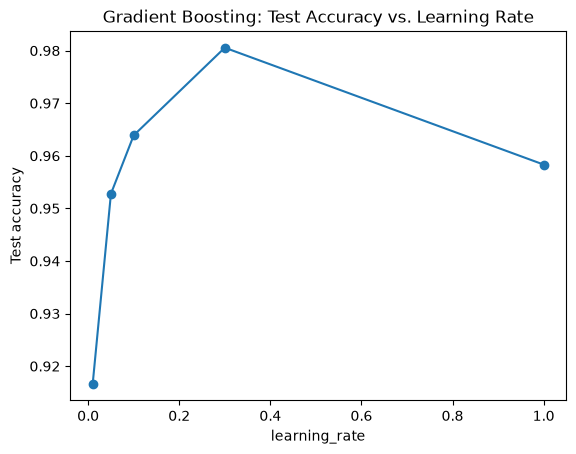

In [6]:

# Plot test accuracy against learning rate

plt.plot(learning_rates , test_accuracies ,marker="o")

plt.xlabel("learning_rate")
plt.ylabel("Test accuracy")
plt.title("Gradient Boosting: Test Accuracy vs. Learning Rate")

plt.show()

Practice 3 — learning_rate sweep

Yes, there is a clear best value: learning_rate=0.3 achieves the highest test accuracy (0.9806).

 Accuracy rises steadily from 0.01 to 0.3, but drops again at learning_rate=1.
 
 0 (0.9583) — a large learning rate causes each boosting stage to overcorrect, making training less stable.
 
  This shows learning_rate has a "sweet spot" rather than a simple "higher is better" relationship.